# 🧠 Proje 1 · Bölüm 3 — Derin öğrenme: Evrişimli Sinir Ağı (CNN) ve Transfer Öğrenme
**Seviye: İleri**

**CNN'i bir radyoloji asistanına benzetebiliriz:**
* İlk katmanlar **kenarları ve çizgileri** fark eder,
* Orta katmanlar bunları birleştirip **dokuları ve şekilleri** (halka şeklinde kontrastlanma, kitle sınırı) tanır,
* Son katmanlar tüm ipuçlarını toplayıp **karar** verir.

Bunların hiçbirini biz tarif etmiyoruz: model **örneklerden** öğreniyor. Bu yüzden çok veri ister. Elimizde ise yalnızca ~200 eğitim görüntüsü var. Bu bölümde iki yolu karşılaştıracağız:

| | Yaklaşım | Benzetme |
|---|---|---|
| **A** | **Sıfırdan CNN** | Tıp fakültesine hiç gitmemiş birine 200 MR göstererek radyoloji öğretmek |
| **B** | **Transfer öğrenme** (MobileNetV2) | 1,2 milyon gündelik fotoğrafla "görmeyi" zaten öğrenmiş birine yalnızca MR'ı öğretmek |

In [1]:
# Google Colab'da çalışıyorsanız: proje klasörünü (zip) yükleyip açın
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 01_Beyin_MR_Tumor.zip dosyasını seçin")
    yuklenen = files.upload()
    !unzip -q -o 01_Beyin_MR_Tumor.zip
    %cd 01_Beyin_MR_Tumor
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/01_Beyin_MR_Tumor


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
plt.rcParams["figure.dpi"] = 110

d = np.load("islenmis/veri_128.npz", allow_pickle=True)
X, y, bolum, gruplar = d["X"][..., None], d["y"], d["bolum"], d["grup"]
egt_idx, tst_idx = np.where(bolum == "egitim")[0], np.where(bolum == "test")[0]

# Eğitim verisinin ~%15'i doğrulama (validation) için — yine benzer görüntü gruplarına saygı göstererek
a, b = next(StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=1).split(egt_idx, y[egt_idx], gruplar[egt_idx]))
tr_idx, val_idx = egt_idx[a], egt_idx[b]
print(f"Eğitim: {len(tr_idx)} | Doğrulama: {len(val_idx)} | Test: {len(tst_idx)}")

def rapor(y_gercek, olasilik, esik=0.5, ad=""):
    t = (olasilik >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_gercek, t, labels=[0, 1]).ravel()
    return {"Model": ad, "AUC": roc_auc_score(y_gercek, olasilik), "Doğruluk": (tp + tn) / len(y_gercek),
            "Duyarlılık": tp / (tp + fn), "Özgüllük": tn / (tn + fp), "PPD": tp / max(tp + fp, 1)}

def esik_sec(y_gercek, olasilik):
    """Doğrulama setinde Youden indeksini (duyarlılık + özgüllük - 1) en büyük yapan eşik."""
    fpr, tpr, e = roc_curve(y_gercek, olasilik)
    return float(np.clip(e[np.argmax(tpr - fpr)], 0.05, 0.95))

I0000 00:00:1791818476.843178   17623 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791818478.181738   17623 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Eğitim: 168 | Doğrulama: 34 | Test: 51


## 1. Veri artırma: az veriyi çoğaltmak
Her eğitim turunda görüntüleri **rastgele** çeviriyor, döndürüyor, yakınlaştırıyoruz. Model böylece "aynı tümörün farklı görünümlerini" görür ve ezberlemek yerine genellemeyi öğrenir.

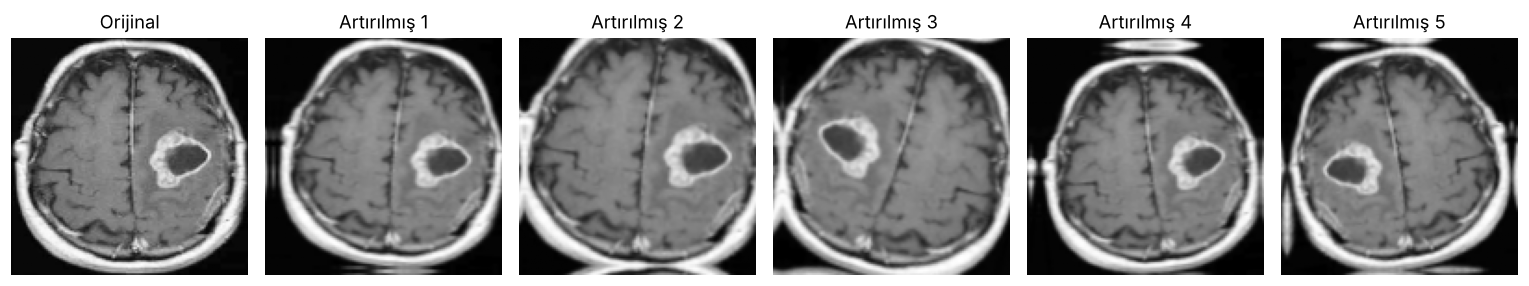

In [3]:
def artirma_kur():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
    ], name="veri_artirma")

keras.utils.set_random_seed(0)
artirma = artirma_kur()
ornek = X[tr_idx[0]][None]
fig, ax = plt.subplots(1, 6, figsize=(14, 2.6))
ax[0].imshow(ornek[0, ..., 0], cmap="gray"); ax[0].set_title("Orijinal")
for k in range(1, 6):
    ax[k].imshow(np.clip(artirma(ornek, training=True)[0, ..., 0], 0, 1), cmap="gray"); ax[k].set_title(f"Artırılmış {k}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 2-A. Sıfırdan küçük bir CNN
4 evrişim katmanı, ≈ 60 bin parametre. (Büyük modellerde bu sayı on milyonlarcadır.)

In [4]:
def kucuk_cnn():
    giris = keras.Input((128, 128, 1))
    x = artirma_kur()(giris)
    for i, f in enumerate([16, 32, 64]):
        x = layers.Conv2D(f, 3, padding="same", activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4), name=f"conv{i+1}")(x)
        x = layers.MaxPooling2D(name=f"pool{i+1}")(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4), name="conv4")(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3)(x)
    cikis = layers.Dense(1, activation="sigmoid", name="karar")(x)
    return keras.Model(giris, cikis, name="kucuk_cnn")

keras.utils.set_random_seed(7)
cnn = kucuk_cnn()
cnn.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
cnn.summary()

Model: "kucuk_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ veri_artirma (Sequential)       │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ karar (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,289 (235.50 KB)

 Trainable params: 60,289 (235.50 KB)

 Non-trainable params: 0 (0.00 B)

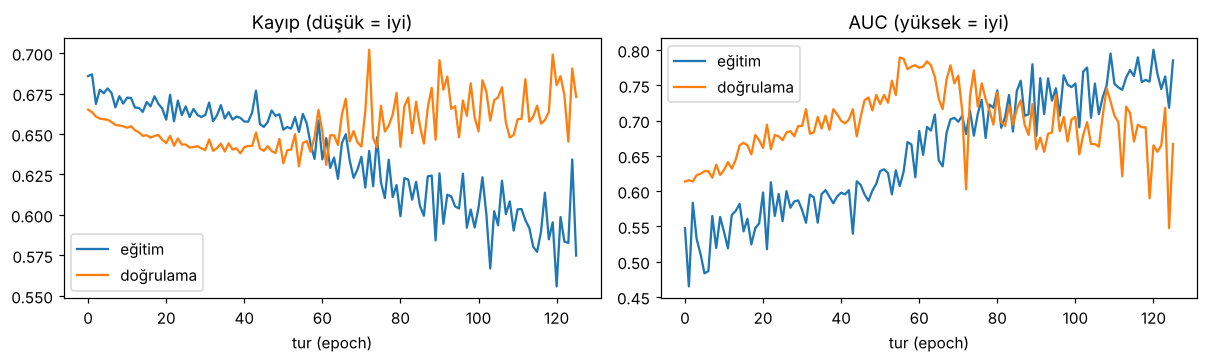

Tur sayısı: 126 | en iyi doğrulama AUC: 0.789


In [5]:
erken_dur = lambda sabir: [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=sabir, restore_best_weights=True)]
gecmis_a = cnn.fit(X[tr_idx], y[tr_idx], validation_data=(X[val_idx], y[val_idx]),
                   epochs=300, batch_size=16, callbacks=erken_dur(70), verbose=0)
h = pd.DataFrame(gecmis_a.history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Kayıp (düşük = iyi)"); ax[0].legend(["eğitim", "doğrulama"])
h[["auc", "val_auc"]].plot(ax=ax[1], title="AUC (yüksek = iyi)"); ax[1].legend(["eğitim", "doğrulama"])
for a in ax: a.set_xlabel("tur (epoch)")
plt.tight_layout(); plt.show()
print("Tur sayısı:", len(h), "| en iyi doğrulama AUC:", round(h.val_auc.max(), 3))

**Nasıl okunur?** Eğitim eğrisi iyileşirken doğrulama eğrisi yerinde sayıyor ya da kötüleşiyorsa model **ezberliyor (aşırı öğrenme / overfitting)** demektir. *Erken durdurma (early stopping)* en iyi doğrulama anındaki ağırlıkları geri yükler.

## 2-B. Transfer öğrenme: hazır eğitilmiş MobileNetV2
**MobileNetV2**, telefonlarda çalışmak için tasarlanmış, ImageNet (1,2 milyon fotoğraf, 1000 sınıf) üzerinde önceden eğitilmiş bir ağdır. Kenar, doku ve şekil algılayan katmanlarını olduğu gibi alıp yalnızca **son karar katmanını** MR verimizle eğiteceğiz. Ardından son katmanları çok küçük adımlarla **ince ayar (fine-tuning)** yapacağız.

> Modelimiz gri tonlu görüntüyü 3 kanala kopyalar ve değerleri MobileNetV2'nin beklediği −1…+1 aralığına çevirir.

In [6]:
AGIRLIK = "onegitimli/mobilenet_v2_0.35_128_no_top.h5"   # ImageNet ağırlıkları (internetsiz kullanım için projede)
taban = keras.applications.MobileNetV2((128, 128, 3), alpha=0.35, include_top=False,
                                       weights=AGIRLIK if os.path.exists(AGIRLIK) else "imagenet")

def transfer_model():
    giris = keras.Input((128, 128, 1))
    x = artirma_kur()(giris)
    x = layers.Concatenate(name="gri_to_rgb")([x, x, x])
    x = layers.Rescaling(2.0, -1.0, name="olcekle")(x)      # 0..1  ->  -1..+1
    x = taban(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3)(x)
    cikis = layers.Dense(1, activation="sigmoid", name="karar")(x)
    return keras.Model(giris, cikis, name="mobilenet_transfer")

keras.utils.set_random_seed(7)
tl = transfer_model()
print(f"Toplam parametre: {tl.count_params():,}  (taban modelin {taban.count_params():,} tanesi hazır geliyor)")

# Aşama 1: taban dondurulmuş, yalnızca karar katmanı öğreniyor
taban.trainable = False
tl.compile(keras.optimizers.Adam(1e-3), "binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
kayip_izle = lambda sabir: [keras.callbacks.EarlyStopping(monitor="val_loss", patience=sabir, restore_best_weights=True)]
g1 = tl.fit(X[tr_idx], y[tr_idx], validation_data=(X[val_idx], y[val_idx]), epochs=80, batch_size=16, callbacks=kayip_izle(20), verbose=0)
k1 = min(g1.history["val_loss"]); asama1_agirlik = tl.get_weights()
print(f"Aşama 1 (dondurulmuş)  doğrulama kaybı {k1:.3f} | AUC {max(g1.history['val_auc']):.3f}")

# Aşama 2: yalnızca son blokları çok küçük öğrenme hızıyla "ince ayar"
taban.trainable = True
for L in taban.layers[:-20]:
    L.trainable = False
tl.compile(keras.optimizers.Adam(1e-5), "binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
g2 = tl.fit(X[tr_idx], y[tr_idx], validation_data=(X[val_idx], y[val_idx]), epochs=60, batch_size=16, callbacks=kayip_izle(15), verbose=0)
k2 = min(g2.history["val_loss"])
print(f"Aşama 2 (ince ayar)    doğrulama kaybı {k2:.3f} | AUC {max(g2.history['val_auc']):.3f}")
if k2 >= k1:
    tl.set_weights(asama1_agirlik); print("→ İnce ayar doğrulamada iyileştirmedi; aşama 1 modeli kullanılıyor.")
else:
    print("→ İnce ayarlı model kullanılıyor.")

Toplam parametre: 411,489  (taban modelin 410,208 tanesi hazır geliyor)


Aşama 1 (dondurulmuş)  doğrulama kaybı 0.397 | AUC 0.903


Aşama 2 (ince ayar)    doğrulama kaybı 0.398 | AUC 0.894
→ İnce ayar doğrulamada iyileştirmedi; aşama 1 modeli kullanılıyor.


## 3. Test setinde karşılaştırma
Karar eşiğini **test setine bakmadan**, doğrulama setinde seçiyoruz (aksi hâlde sonucu kendimize göre ayarlamış oluruz).

In [7]:
sonuc = []
p_test = {}
for ad, m in [("Sıfırdan CNN", cnn), ("Transfer öğrenme (MobileNetV2)", tl)]:
    esik = esik_sec(y[val_idx], m.predict(X[val_idx], verbose=0).ravel())
    p_test[ad] = m.predict(X[tst_idx], verbose=0).ravel()
    r = rapor(y[tst_idx], p_test[ad], esik, ad); r["Eşik"] = esik; sonuc.append(r)
klasik = pd.read_csv("islenmis/klasik_sonuclar.csv", index_col=0)
karsilastirma = pd.concat([klasik, pd.DataFrame(sonuc).set_index("Model")]).round(3)
karsilastirma

,AUC,Doğruluk,Duyarlılık,Özgüllük,PPD,Eşik
Model,,,,,,
Lojistik regresyon,0.942,0.843,0.839,0.85,0.897,NaN
k-En yakın komşu,0.769,0.706,0.903,0.40,0.700,NaN
Rastgele orman,0.850,0.765,0.935,0.50,0.744,NaN
Sıfırdan CNN,0.823,0.824,0.871,0.75,0.844,0.519
Transfer öğrenme (MobileNetV2),0.947,0.824,0.742,0.95,0.958,0.493


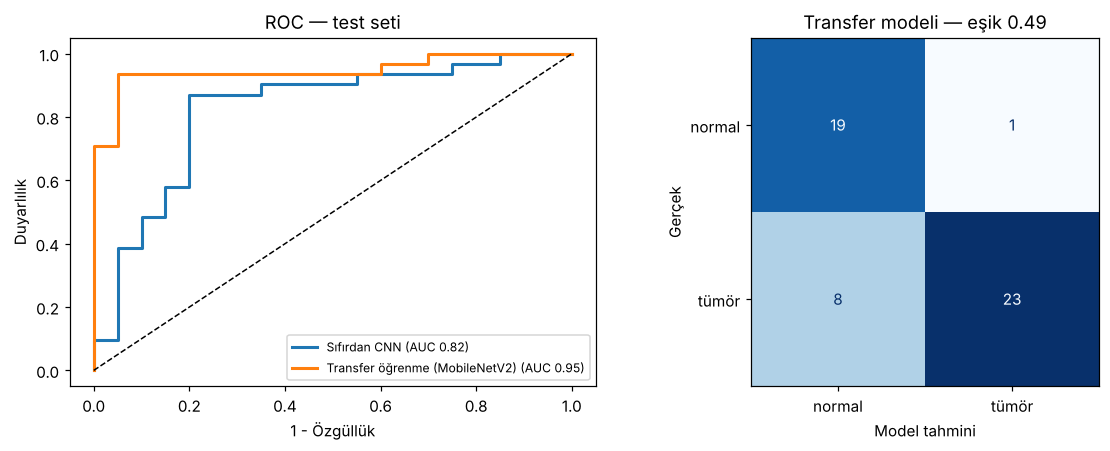

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for ad, p in p_test.items():
    fpr, tpr, _ = roc_curve(y[tst_idx], p); ax[0].plot(fpr, tpr, lw=2, label=f"{ad} (AUC {roc_auc_score(y[tst_idx], p):.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlabel("1 - Özgüllük"); ax[0].set_ylabel("Duyarlılık"); ax[0].legend(fontsize=8); ax[0].set_title("ROC — test seti")
en_iyi = "Transfer öğrenme (MobileNetV2)"; esik_tl = float(karsilastirma.loc[en_iyi, "Eşik"])
ConfusionMatrixDisplay(confusion_matrix(y[tst_idx], p_test[en_iyi] >= esik_tl), display_labels=["normal", "tümör"]).plot(ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title(f"Transfer modeli — eşik {esik_tl:.2f}"); ax[1].set_xlabel("Model tahmini"); ax[1].set_ylabel("Gerçek")
plt.tight_layout(); plt.show()

## 4. Eşik seçimi bir **klinik karardır**, teknik değil
Model bir olasılık verir (0–1). "Kaçıncı olasılıktan sonra tümör diyelim?" sorusunun cevabı kullanım amacına bağlıdır:
* **Tarama** (hiçbir tümörü kaçırmayalım) → düşük eşik → yüksek duyarlılık, daha çok yanlış alarm
* **Doğrulama** (gereksiz girişim olmasın) → yüksek eşik → yüksek özgüllük

In [9]:
satirlar = []
for e in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    r = rapor(y[tst_idx], p_test[en_iyi], esik=e)
    satirlar.append({"Eşik": e, "Duyarlılık": r["Duyarlılık"], "Özgüllük": r["Özgüllük"], "PPD": r["PPD"]})
pd.DataFrame(satirlar).round(2).set_index("Eşik")

,Duyarlılık,Özgüllük,PPD
Eşik,,,
0.1,1.00,0.20,0.66
0.2,0.97,0.35,0.70
0.3,0.94,0.80,0.88
0.4,0.90,0.95,0.97
0.5,0.74,0.95,0.96
0.6,0.71,1.00,1.00
0.7,0.48,1.00,1.00
0.8,0.45,1.00,1.00
0.9,0.35,1.00,1.00


## 5. Hata analizi: model nerede yanılıyor?
Bir hekimin en değerli katkılarından biri budur: modelin hatalarına bakıp **neden** yanıldığını yorumlamak (küçük lezyon? farklı sekans? artefakt?).

Hatalı tahmin sayısı: 9 / 51


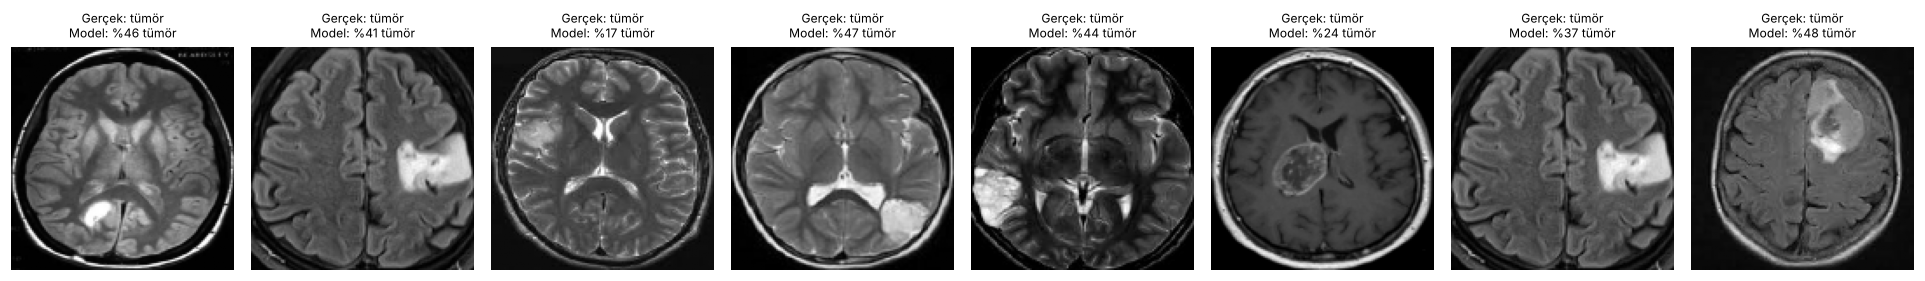

In [10]:
hatali = tst_idx[(p_test[en_iyi] >= esik_tl) != y[tst_idx]]
print("Hatalı tahmin sayısı:", len(hatali), "/", len(tst_idx))
if len(hatali):
    n = min(8, len(hatali))
    fig, ax = plt.subplots(1, n, figsize=(2.2 * n, 2.8), squeeze=False)
    for a, i in zip(ax[0], hatali[:n]):
        p = p_test[en_iyi][list(tst_idx).index(i)]
        a.imshow(X[i, ..., 0], cmap="gray"); a.axis("off")
        a.set_title(f"Gerçek: {'tümör' if y[i] else 'normal'}\nModel: %{100*p:.0f} tümör", fontsize=8)
    plt.tight_layout(); plt.show()

In [11]:
os.makedirs("model", exist_ok=True)
tl.save("model/tumor_mobilenet.keras")
cnn.save("model/tumor_kucuk_cnn.keras")
karsilastirma.to_csv("islenmis/tum_sonuclar.csv")
import json
json.dump({"esik": esik_tl, "val_idx": val_idx.tolist()}, open("model/esik.json", "w"))
print("Kaydedildi → model/tumor_mobilenet.keras, model/tumor_kucuk_cnn.keras")

Kaydedildi → model/tumor_mobilenet.keras, model/tumor_kucuk_cnn.keras


## ✅ Çıkarımlar
* Küçük veride **transfer öğrenme**, sıfırdan eğitilen ağa göre belirgin biçimde daha iyi sonuç verir. Bu yüzden tıbbi görüntülemede neredeyse her proje hazır eğitilmiş bir modelle başlar.
* Basit radyomiks + lojistik regresyon da şaşırtıcı derecede iyi olabilir: **derin öğrenme her zaman tek doğru değildir.**
* Test setinde yalnızca ~50 görüntü var; sonuçların **güven aralığı geniştir**. Gerçek bir çalışmada **dış doğrulama** (başka hastane/cihaz) şarttır.

💡 **Araştırma fikirleri**
1. Hastanenizin kendi verisiyle eğitip bu kamu verisinde **dış doğrulama** yapmak (ya da tersi).
2. ImageNet yerine tıbbi görüntülerle önceden eğitilmiş ağlar (**RadImageNet**, MedSAM vb.) ile karşılaştırma.
3. Sekans (T1/T2/FLAIR) farklılığının başarıya etkisi — **alan kayması (domain shift)** analizi.
4. "Ne kadar veri yeter?" — öğrenme eğrisi çalışması (50, 100, 200… görüntü).